# Notebook 01 — Data Acquisition, Provenance and Critical Data Understanding

**Project:** A Machine-Learning Pipeline for Network Intrusion Detection: Comparing Models and Feature Sets, and Assessing Cross-Dataset Generalisation



---



## 1. Environment and project structure

This cell mounts Google Drive so every artefact survives a runtime reset.
It builds the fixed folder structure used by all five notebooks.
Nothing is downloaded yet and nothing is overwritten if it already exists.
Run it once at the start of every session.

In [ ]:
# --- Drive mount and project skeleton -------------------------------------
import os, sys, json, hashlib, warnings, zipfile, shutil, time, re
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/nids_benchmark")
else:
    PROJECT = Path.home() / "nids_benchmark"

RAW       = PROJECT / "data" / "raw"
INTERIM   = PROJECT / "data" / "interim"
PROCESSED = PROJECT / "data" / "processed"
ARTIFACTS = PROJECT / "artifacts"
FIGURES   = PROJECT / "figures" / "nb01"
REPORTS   = PROJECT / "reports" / "nb01"

for p in [RAW, INTERIM, PROCESSED, ARTIFACTS, FIGURES, REPORTS]:
    p.mkdir(parents=True, exist_ok=True)

# Working copies live on local disk for speed then get synced to Drive.
LOCAL = Path("/content/work") if IN_COLAB else PROJECT / "work"
LOCAL.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT)
print("Raw data     :", RAW)
print("Reports      :", REPORTS)
print("Colab        :", IN_COLAB)


Project root : /content/drive/MyDrive/nids_benchmark
Raw data     : /content/drive/MyDrive/nids_benchmark/data/raw
Reports      : /content/drive/MyDrive/nids_benchmark/reports/nb01
Colab        : True


This cell fixes the global random seed for every library we will use.
It records exact package versions into a run manifest for reproducibility.
The manifest is the evidence that supports the reproducibility claim in Section 3.5.
Never change the seed value between notebooks.

In [ ]:
# --- Determinism and version manifest -------------------------------------
import random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "savefig.bbox": "tight", "font.size": 9})

MANIFEST = {
    "notebook": "01_data_understanding",
    "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "python": sys.version.split()[0],
    "packages": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "datasets": {},
    "findings": {},
}

print(json.dumps(MANIFEST["packages"], indent=2))
print("Seed fixed at", SEED)


{
  "numpy": "2.0.2",
  "pandas": "2.2.2",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.10.0"
}
Seed fixed at 42


## 2. Provenance and licence record

The proposal (Section 3.5) requires provenance, licensing, collection environment, collection
period and known limitations to be documented **before** modelling. This is a static record —
it goes straight into the dissertation. Verify every URL yourself before submission; dataset
hosting for all three of these has moved at least once.

This cell records the provenance and licence facts for the three datasets.
It is a static reference table rather than a computation.
Every URL must be re-checked by you before the dissertation is submitted.
Dataset hosting for all three has moved at least once historically.

In [ ]:
# --- Provenance record (verify URLs before submission) --------------------
PROVENANCE = {
    "cicids2017": {
        "full_name": "CIC-IDS2017 Intrusion Detection Evaluation Dataset",
        "publisher": "Canadian Institute for Cybersecurity, University of New Brunswick",
        "official_page": "https://www.unb.ca/cic/datasets/ids-2017.html",
        "citation": "Sharafaldin, Lashkari and Ghorbani (2018), ICISSP, pp. 108-116",
        "capture_period": "Mon 3 July 2017 09:00 to Fri 7 July 2017 17:00",
        "environment": "Purpose-built testbed, 25 profiled users, HTTP/HTTPS/FTP/SSH/email",
        "feature_basis": "Bidirectional flows extracted with CICFlowMeter (~78 numeric features)",
        "licence_note": "Free for research use with citation. Confirm current terms on the CIC page.",
        "role": "Principal development dataset",
        "known_issues": [
            "Header names carry leading whitespace",
            "Flow Bytes/s and Flow Packets/s contain Infinity and NaN when duration is zero",
            "Web Attack labels contain a non-UTF-8 dash character",
            "Fwd Header Length is duplicated as a second column",
            "Substantial exact-duplicate rows; documented label errors (Engelen et al. 2021)",
        ],
    },
    "unswnb15": {
        "full_name": "UNSW-NB15",
        "publisher": "Australian Centre for Cyber Security, UNSW Canberra",
        "official_page": "https://research.unsw.edu.au/projects/unsw-nb15-dataset",
        "citation": "Moustafa and Slay (2015), MilCIS, IEEE",
        "capture_period": "2015, two simulation periods",
        "environment": "IXIA PerfectStorm cyber range, 3 servers and 2 routers",
        "feature_basis": "Argus and Bro-derived flow features (49 columns incl. labels)",
        "licence_note": "Free for academic research in perpetuity. Commercial use prohibited.",
        "role": "Primary cross-dataset transfer target",
        "known_issues": [
            "Two distributions exist: full 2.54M-record 4-part CSV and a curated 175k/82k split",
            "The curated split is already partitioned which conflicts with our own split policy",
            "Feature names differ entirely from CICFlowMeter naming",
        ],
    },
    "nslkdd": {
        "full_name": "NSL-KDD",
        "publisher": "Canadian Institute for Cybersecurity / Tavallaee et al.",
        "official_page": "https://www.unb.ca/cic/datasets/nsl.html",
        "citation": "Tavallaee, Bagheri, Lu and Ghorbani (2009), CISDA, pp. 1-6",
        "capture_period": "Derived from DARPA 1998 / KDD Cup 99",
        "environment": "1998 simulated US Air Force LAN",
        "feature_basis": "Connection records: 41 features incl. host-based content features",
        "licence_note": "Free for research use with citation.",
        "role": "Deliberately hard transfer case; NOT representative of modern traffic",
        "known_issues": [
            "Not flow-based, so most CICFlowMeter concepts have no equivalent",
            "Carries a 'difficulty' column that is metadata and would be leakage if modelled",
            "Attack taxonomy (DoS/Probe/R2L/U2R) does not align with the other two datasets",
            "Test set intentionally contains attack types absent from the training set",
        ],
    },
}

prov_df = pd.DataFrame([
    {"dataset": k,
     "publisher": v["publisher"],
     "captured": v["capture_period"],
     "feature_basis": v["feature_basis"],
     "role": v["role"],
     "n_known_issues": len(v["known_issues"])}
    for k, v in PROVENANCE.items()
])
display(prov_df)
MANIFEST["provenance"] = PROVENANCE


,dataset,publisher,captured,feature_basis,role,n_known_issues
0,cicids2017,"Canadian Institute for Cybersecurity, Universi...",Mon 3 July 2017 09:00 to Fri 7 July 2017 17:00,Bidirectional flows extracted with CICFlowMete...,Principal development dataset,5
1,unswnb15,"Australian Centre for Cyber Security, UNSW Can...","2015, two simulation periods",Argus and Bro-derived flow features (49 column...,Primary cross-dataset transfer target,3
2,nslkdd,Canadian Institute for Cybersecurity / Tavalla...,Derived from DARPA 1998 / KDD Cup 99,Connection records: 41 features incl. host-bas...,Deliberately hard transfer case; NOT represent...,4


## 3. Dataset acquisition

Three routes are provided in order of reliability on Colab.

1. **Kaggle API** — most reliable, needs `kaggle.json`
2. **Direct HTTP** — official mirrors, sometimes rate-limited or offline
3. **Manual upload** — you place the archives in Drive yourself

Run route 1. If it fails, run route 2. If that fails, run route 3. Only one needs to succeed.

Kaggle now issues a single token string instead of the older kaggle.json file.
This cell accepts either format and caches it to Drive for future sessions.
The token is entered through a hidden prompt so it never appears in saved output.
Skip this cell entirely if you intend to download the datasets manually.

In [ ]:
# --- Route 1a: Kaggle credentials -----------------------------------------
# Kaggle migrated from kaggle.json to a single access token (KGAT_...).
# Both formats are supported here. The token is never hard-coded in the notebook.
import getpass, subprocess

KAGGLE_OK = False
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(exist_ok=True)

token_store = PROJECT / "kaggle_access_token.txt"   # new format, cached on Drive
json_store  = PROJECT / "kaggle.json"               # legacy format, cached on Drive

try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"],
                   check=False)
    tok = None

    if token_store.exists():
        tok = token_store.read_text().strip()
        print("Using cached access token from Drive.")
    elif json_store.exists():
        shutil.copy(json_store, kaggle_dir / "kaggle.json")
        os.chmod(kaggle_dir / "kaggle.json", 0o600)
        print("Using cached legacy kaggle.json from Drive.")
    else:
        print("Kaggle > Settings > API > Create New Token, then paste the KGAT_ string.")
        tok = getpass.getpass("Kaggle access token: ").strip()
        if tok:
            token_store.write_text(tok)
            print("Token cached to Drive. You will not be asked again.")

    if tok:
        os.environ["KAGGLE_API_TOKEN"] = tok
        (kaggle_dir / "access_token").write_text(tok)
        os.chmod(kaggle_dir / "access_token", 0o600)

    KAGGLE_OK = os.system("kaggle datasets list -s nsl-kdd > /dev/null 2>&1") == 0
    print("Kaggle authentication:", "OK" if KAGGLE_OK else "FAILED")
    if not KAGGLE_OK:
        print("Check the token is current and that you accepted each dataset's terms.")
except Exception as e:
    print("Kaggle setup failed:", e)
    print("Use the direct download route or the manual route below.")


Kaggle > Settings > API > Create New Token, then paste the KGAT_ string.
Kaggle access token: ··········
Token cached to Drive. You will not be asked again.
Kaggle authentication: OK


This cell downloads all three datasets into the raw data folder.
Existing downloads are skipped so re-running the notebook stays cheap.
Each dataset lands in its own subfolder to keep provenance unambiguous.
Expect roughly two gigabytes and several minutes on a good connection.

In [ ]:
# --- Route 1b: Kaggle download --------------------------------------------
# NOTE: verify these slugs are still live. Mirrors get taken down without notice.
KAGGLE_SLUGS = {
    "cicids2017": "chethuhn/network-intrusion-dataset",
    "unswnb15":   "mrwellsdavid/unsw-nb15",
    "nslkdd":     "hassan06/nslkdd",
}

def kaggle_fetch(key, slug):
    dest = RAW / key
    dest.mkdir(parents=True, exist_ok=True)
    if any(dest.rglob("*.csv")) or any(dest.rglob("*.txt")):
        print(f"[skip] {key} already present at {dest}")
        return True
    cmd = f'kaggle datasets download -d {slug} -p "{dest}" --unzip'
    print("[run ]", cmd)
    rc = os.system(cmd)
    ok = rc == 0 and (any(dest.rglob("*.csv")) or any(dest.rglob("*.txt")))
    print(f"[{'ok  ' if ok else 'fail'}] {key}")
    return ok

if KAGGLE_OK:
    for k, s in KAGGLE_SLUGS.items():
        kaggle_fetch(k, s)
else:
    print("Kaggle not configured. Use the direct or manual routes.")


[run ] kaggle datasets download -d chethuhn/network-intrusion-dataset -p "/content/drive/MyDrive/nids_benchmark/data/raw/cicids2017" --unzip
[ok  ] cicids2017
[run ] kaggle datasets download -d mrwellsdavid/unsw-nb15 -p "/content/drive/MyDrive/nids_benchmark/data/raw/unswnb15" --unzip
[ok  ] unswnb15
[run ] kaggle datasets download -d hassan06/nslkdd -p "/content/drive/MyDrive/nids_benchmark/data/raw/nslkdd" --unzip
[ok  ] nslkdd


This cell is the direct download fallback using official and mirror hosts.
Run it only for datasets that the Kaggle route failed to retrieve.
The CIC host is plain HTTP and is occasionally slow or unreachable.
Set the flags to True only for the datasets you actually still need.

In [ ]:
# --- Route 2: direct HTTP fallback ----------------------------------------
FETCH_CIC   = False   # set True only if cicids2017 is still missing
FETCH_NSL   = False   # set True only if nslkdd is still missing

DIRECT = {
    "cicids2017": "http://205.174.165.80/CICDataset/CIC-IDS-2017/Dataset/MachineLearningCSV.zip",
    "nslkdd_train": "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
    "nslkdd_test":  "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
}

if FETCH_CIC:
    d = RAW / "cicids2017"; d.mkdir(parents=True, exist_ok=True)
    os.system(f'wget -nc -q --show-progress -P "{d}" "{DIRECT["cicids2017"]}"')
    for z in d.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(d)
        print("extracted", z.name)

if FETCH_NSL:
    d = RAW / "nslkdd"; d.mkdir(parents=True, exist_ok=True)
    os.system(f'wget -nc -q -O "{d}/KDDTrain+.txt" "{DIRECT["nslkdd_train"]}"')
    os.system(f'wget -nc -q -O "{d}/KDDTest+.txt"  "{DIRECT["nslkdd_test"]}"')

print("Direct fallback finished. UNSW-NB15 has no stable direct link and must come")
print("from Kaggle or from the official UNSW page by manual download.")


Direct fallback finished. UNSW-NB15 has no stable direct link and must come
from Kaggle or from the official UNSW page by manual download.


This cell inventories whatever actually landed in the raw folder.
It hashes every file so integrity can be proven if a result is ever questioned.
Hashing large files takes a minute and only needs to happen once.
The hashes are written into the run manifest and belong in your appendix.

In [ ]:
# --- Inventory and integrity hashing --------------------------------------
def sha256_of(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(chunk), b""):
            h.update(blk)
    return h.hexdigest()

HASH_CACHE = REPORTS / "file_hashes.json"
hashes = json.loads(HASH_CACHE.read_text()) if HASH_CACHE.exists() else {}

inventory = []
for key in ["cicids2017", "unswnb15", "nslkdd"]:
    folder = RAW / key
    files = sorted([p for p in folder.rglob("*")
                    if p.is_file() and p.suffix.lower() in {".csv", ".txt", ".arff"}])
    for p in files:
        rel = str(p.relative_to(RAW))
        if rel not in hashes:
            hashes[rel] = sha256_of(p)
        inventory.append({"dataset": key, "file": p.name,
                          "size_mb": round(p.stat().st_size / 1e6, 2),
                          "sha256_head": hashes[rel][:16]})

HASH_CACHE.write_text(json.dumps(hashes, indent=2))
inv_df = pd.DataFrame(inventory)
display(inv_df)
MANIFEST["file_inventory"] = inventory

for key in ["cicids2017", "unswnb15", "nslkdd"]:
    n = (inv_df.dataset == key).sum() if len(inv_df) else 0
    print(f"{key:12s}: {n} data files")


,dataset,file,size_mb,sha256_head
0,cicids2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,77.12,6ff1580f5f81c0ae
1,cicids2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,76.91,ca1824c51bfbb7b3
2,cicids2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,58.32,53a41c24d570ea83
3,cicids2017,Monday-WorkingHours.pcap_ISCX.csv,176.93,852c4beb34eda186
4,cicids2017,Thursday-WorkingHours-Afternoon-Infilteration....,83.10,6bcda3857c250467
5,cicids2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,52.02,d67066211fb1689c
6,cicids2017,Tuesday-WorkingHours.pcap_ISCX.csv,135.08,52b8692ae8c7d2ed
7,cicids2017,Wednesday-workingHours.pcap_ISCX.csv,225.17,893c27dc968bf7a8
8,unswnb15,NUSW-NB15_features.csv,0.00,c55f19cceebb6360
9,unswnb15,UNSW-NB15_1.csv,168.98,7d851bbeabd27894


cicids2017  : 8 data files
unswnb15    : 8 data files
nslkdd      : 16 data files


## 4. Loading

This cell defines a memory aware downcast helper for wide numeric tables.
It only shrinks a column when doing so cannot lose integer precision.
This matters because flow duration values exceed the exact range of float32.
Blind downcasting is a silent corruption risk that many published pipelines ignore.

In [ ]:
# --- Safe downcasting ------------------------------------------------------
FLOAT32_EXACT_INT_LIMIT = 2 ** 24   # 16,777,216

def safe_downcast(df, verbose=True):
    """Shrink numeric dtypes only where precision cannot be lost."""
    before = df.memory_usage(deep=True).sum() / 1e6
    for col in df.columns:
        s = df[col]
        if not pd.api.types.is_numeric_dtype(s):
            continue
        finite = s.replace([np.inf, -np.inf], np.nan)
        mx = finite.abs().max()
        if pd.isna(mx):
            continue
        if pd.api.types.is_integer_dtype(s):
            df[col] = pd.to_numeric(s, downcast="integer")
        elif mx < FLOAT32_EXACT_INT_LIMIT:
            df[col] = s.astype(np.float32)
        # else: leave as float64 to protect large flow-duration values
    after = df.memory_usage(deep=True).sum() / 1e6
    if verbose:
        print(f"    memory {before:,.0f} MB -> {after:,.0f} MB")
    return df


This cell loads the CIC-IDS2017 daily CSV files and stacks them together.
Column names are stripped because the raw headers carry leading spaces.
The source file name is retained so day level effects can be inspected later.
Latin-1 encoding is used because the web attack labels contain a non UTF-8 dash.

In [ ]:
# --- CIC-IDS2017 loader ----------------------------------------------------
def load_cicids2017(folder=RAW / "cicids2017"):
    files = sorted([p for p in folder.rglob("*.csv")])
    if not files:
        raise FileNotFoundError(f"No CSVs under {folder}")
    print(f"Loading {len(files)} CIC-IDS2017 files")
    parts, per_file = [], []
    for p in files:
        d = pd.read_csv(p, encoding="latin-1", low_memory=False)
        d.columns = [c.strip() for c in d.columns]
        d["__source_file"] = p.name
        per_file.append({"file": p.name, "rows": len(d), "cols": d.shape[1] - 1})
        parts.append(d)
        print(f"  {p.name:60s} {len(d):>9,} rows")
    df = pd.concat(parts, ignore_index=True)
    del parts
    label_col = "Label" if "Label" in df.columns else df.columns[-2]
    df = df.rename(columns={label_col: "label_raw"})
    df["label_raw"] = (df["label_raw"].astype(str).str.strip()
                       .str.replace(r"[^\x00-\x7F]+", "-", regex=True))
    print(f"\nCombined: {df.shape[0]:,} rows x {df.shape[1]} cols")
    return safe_downcast(df), pd.DataFrame(per_file)

try:
    cic, cic_files = load_cicids2017()
    display(cic_files)
except Exception as e:
    cic, cic_files = None, None
    print("CIC-IDS2017 load failed:", e)


Loading 8 CIC-IDS2017 files
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv               225,745 rows
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv           286,467 rows
  Friday-WorkingHours-Morning.pcap_ISCX.csv                      191,033 rows
  Monday-WorkingHours.pcap_ISCX.csv                              529,918 rows
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv    288,602 rows
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv         170,366 rows
  Tuesday-WorkingHours.pcap_ISCX.csv                             445,909 rows
  Wednesday-workingHours.pcap_ISCX.csv                           692,703 rows

Combined: 2,830,743 rows x 80 cols
    memory 2,179 MB -> 1,262 MB


,file,rows,cols
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79


This cell loads UNSW-NB15 and adapts to whichever distribution you obtained.
The full four part release is preferred because we want to control our own split.
The pre-split release is accepted as a fallback and is flagged in the manifest.
Which version you used must be stated in the dissertation methodology chapter.

In [ ]:
# --- UNSW-NB15 loader ------------------------------------------------------
UNSW_49 = ["srcip","sport","dstip","dsport","proto","state","dur","sbytes","dbytes",
           "sttl","dttl","sloss","dloss","service","sload","dload","spkts","dpkts",
           "swin","dwin","stcpb","dtcpb","smeansz","dmeansz","trans_depth",
           "res_bdy_len","sjit","djit","stime","ltime","sintpkt","dintpkt","tcprtt",
           "synack","ackdat","is_sm_ips_ports","ct_state_ttl","ct_flw_http_mthd",
           "is_ftp_login","ct_ftp_cmd","ct_srv_src","ct_srv_dst","ct_dst_ltm",
           "ct_src_ltm","ct_src_dport_ltm","ct_dst_sport_ltm","ct_dst_src_ltm",
           "attack_cat","label"]

def load_unswnb15(folder=RAW / "unswnb15"):
    csvs = sorted([p for p in folder.rglob("*.csv")])
    if not csvs:
        raise FileNotFoundError(f"No CSVs under {folder}")

    parts = [p for p in csvs if re.search(r"UNSW[-_]NB15[-_]?[1-4]\.csv$", p.name, re.I)]
    if len(parts) >= 2:
        variant = "full_4part"
        print(f"Found full release: {len(parts)} part files")
        dfs = []
        for p in sorted(parts):
            d = pd.read_csv(p, header=None, names=UNSW_49, low_memory=False)
            d["__source_file"] = p.name
            dfs.append(d)
            print(f"  {p.name:40s} {len(d):>9,} rows")
        df = pd.concat(dfs, ignore_index=True)
        df["attack_cat"] = df["attack_cat"].fillna("Normal").astype(str).str.strip()
        df["label_raw"] = df["attack_cat"]
    else:
        variant = "presplit_175k_82k"
        tr = [p for p in csvs if "train" in p.name.lower()]
        te = [p for p in csvs if "test"  in p.name.lower()]
        use = sorted(tr + te) or csvs
        print(f"Full release not found. Using pre-split files: {[p.name for p in use]}")
        dfs = []
        for p in use:
            d = pd.read_csv(p, low_memory=False)
            d["__source_file"] = p.name
            d["__orig_partition"] = "train" if "train" in p.name.lower() else "test"
            dfs.append(d)
        df = pd.concat(dfs, ignore_index=True)
        df.columns = [c.strip() for c in df.columns]
        cat = "attack_cat" if "attack_cat" in df.columns else None
        df["label_raw"] = df[cat].astype(str).str.strip() if cat else df["label"].astype(str)

    print(f"\nCombined: {df.shape[0]:,} rows x {df.shape[1]} cols  [variant={variant}]")
    return safe_downcast(df), variant

try:
    unsw, unsw_variant = load_unswnb15()
except Exception as e:
    unsw, unsw_variant = None, None
    print("UNSW-NB15 load failed:", e)


Found full release: 4 part files
  UNSW-NB15_1.csv                            700,001 rows
  UNSW-NB15_2.csv                            700,001 rows
  UNSW-NB15_3.csv                            700,001 rows
  UNSW-NB15_4.csv                            440,044 rows

Combined: 2,540,047 rows x 51 cols  [variant=full_4part]
    memory 2,313 MB -> 1,815 MB


This cell loads NSL-KDD from the plain text files using the documented schema.
The forty one feature names come from the original KDD Cup 99 task definition.
A difficulty column is present in NSL-KDD and is metadata rather than a feature.
Treating difficulty as a predictor would be leakage so it is isolated immediately.

In [ ]:
# --- NSL-KDD loader --------------------------------------------------------
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label_raw","difficulty"]

NSL_ATTACK_FAMILY = {
    **{a: "DoS"   for a in ["neptune","back","land","pod","smurf","teardrop","apache2",
                            "udpstorm","processtable","mailbomb","worm"]},
    **{a: "Probe" for a in ["ipsweep","nmap","portsweep","satan","mscan","saint"]},
    **{a: "R2L"   for a in ["ftp_write","guess_passwd","imap","multihop","phf","spy",
                            "warezclient","warezmaster","sendmail","named","snmpgetattack",
                            "snmpguess","xlock","xsnoop","httptunnel"]},
    **{a: "U2R"   for a in ["buffer_overflow","loadmodule","perl","rootkit","ps",
                            "sqlattack","xterm"]},
    "normal": "Normal",
}

def load_nslkdd(folder=RAW / "nslkdd"):
    cand = [p for p in folder.rglob("*") if p.is_file()
            and re.search(r"KDD(Train|Test)\+.*\.(txt|csv|arff)$", p.name, re.I)
            and "20Percent" not in p.name]
    cand = [p for p in cand if p.suffix.lower() in {".txt", ".csv"}]
    if not cand:
        raise FileNotFoundError(f"No KDDTrain+/KDDTest+ files under {folder}")
    dfs = []
    for p in sorted(cand):
        d = pd.read_csv(p, header=None, names=NSL_COLS, low_memory=False)
        d["__source_file"] = p.name
        d["__orig_partition"] = "train" if "train" in p.name.lower() else "test"
        dfs.append(d)
        print(f"  {p.name:30s} {len(d):>9,} rows")
    df = pd.concat(dfs, ignore_index=True)
    df["label_raw"] = df["label_raw"].astype(str).str.strip()
    df["attack_family"] = df["label_raw"].map(NSL_ATTACK_FAMILY).fillna("Unknown")
    print(f"\nCombined: {df.shape[0]:,} rows x {df.shape[1]} cols")
    return safe_downcast(df)

try:
    nsl = load_nslkdd()
except Exception as e:
    nsl = None
    print("NSL-KDD load failed:", e)

DATASETS = {k: v for k, v in
            {"cicids2017": cic, "unswnb15": unsw, "nslkdd": nsl}.items() if v is not None}
print("\nLoaded:", list(DATASETS))


  KDDTest+.txt                      22,544 rows
  KDDTrain+.txt                    125,973 rows
  KDDTest+.txt                      22,544 rows
  KDDTrain+.txt                    125,973 rows

Combined: 297,034 rows x 46 cols
    memory 206 MB -> 143 MB

Loaded: ['cicids2017', 'unswnb15', 'nslkdd']


## 5. Structural profile

This cell reports shape and dtype and memory footprint for each dataset.
It is the first sanity check that the files loaded exactly as expected.
Row counts should be compared against the published figures in the literature.
Any mismatch here invalidates everything downstream so check it carefully.

In [ ]:
# --- Structural profile ----------------------------------------------------
EXPECTED = {"cicids2017": 2830743, "unswnb15": 2540044, "nslkdd": 148517}

rows = []
for name, df in DATASETS.items():
    feat_cols = [c for c in df.columns if not c.startswith("__")]
    num = df[feat_cols].select_dtypes(include=[np.number]).shape[1]
    obj = df[feat_cols].select_dtypes(include=["object", "category"]).shape[1]
    exp = EXPECTED.get(name)
    rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(feat_cols),
        "numeric": num,
        "categorical": obj,
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        "expected_rows": exp,
        "row_delta": (len(df) - exp) if exp else None,
    })

struct_df = pd.DataFrame(rows)
display(struct_df)
MANIFEST["structure"] = rows

for r in rows:
    if r["row_delta"] not in (None, 0):
        print(f"NOTE  {r['dataset']}: {r['row_delta']:+,} rows vs the commonly cited figure. "
              f"Explain this in the methodology (different release or partial download).")


,dataset,rows,columns,numeric,categorical,memory_MB,expected_rows,row_delta
0,cicids2017,2830743,79,78,1,1261.8,2830743,0
1,unswnb15,2540047,50,40,10,1815.1,2540044,3
2,nslkdd,297034,44,39,5,143.1,148517,148517


NOTE  unswnb15: +3 rows vs the commonly cited figure. Explain this in the methodology (different release or partial download).
NOTE  nslkdd: +148,517 rows vs the commonly cited figure. Explain this in the methodology (different release or partial download).


This cell prints the full column list of each dataset side by side.
Seeing the raw schemas is what makes the mapping problem concrete.
Naming conventions differ completely between the three sources.
Read this output carefully because Section 9 depends on it.

In [ ]:
# --- Column inventories ----------------------------------------------------
for name, df in DATASETS.items():
    cols = [c for c in df.columns if not c.startswith("__")]
    print(f"\n{'='*78}\n{name.upper()}  ({len(cols)} columns)\n{'='*78}")
    for i in range(0, len(cols), 3):
        print("  " + "".join(f"{c[:24]:<26}" for c in cols[i:i+3]))



CICIDS2017  (79 columns)
  Destination Port          Flow Duration             Total Fwd Packets         
  Total Backward Packets    Total Length of Fwd Pack  Total Length of Bwd Pack  
  Fwd Packet Length Max     Fwd Packet Length Min     Fwd Packet Length Mean    
  Fwd Packet Length Std     Bwd Packet Length Max     Bwd Packet Length Min     
  Bwd Packet Length Mean    Bwd Packet Length Std     Flow Bytes/s              
  Flow Packets/s            Flow IAT Mean             Flow IAT Std              
  Flow IAT Max              Flow IAT Min              Fwd IAT Total             
  Fwd IAT Mean              Fwd IAT Std               Fwd IAT Max               
  Fwd IAT Min               Bwd IAT Total             Bwd IAT Mean              
  Bwd IAT Std               Bwd IAT Max               Bwd IAT Min               
  Fwd PSH Flags             Bwd PSH Flags             Fwd URG Flags             
  Bwd URG Flags             Fwd Header Length         Bwd Header Length         
  

## 6. Data quality audit

This is the section that determines the cleaning rules in Notebook 02. Four things matter:

- **Missing and infinite values** — CIC-IDS2017 divides by flow duration, which is sometimes zero
- **Duplicate rows** — the proposal (Section 3.5) mandates de-duplication *before* splitting
- **Feature-identical rows with conflicting labels** — direct evidence of label noise
- **Constant / near-constant columns** — carry no information and inflate feature counts

This cell audits missing values and infinities and duplicates and constant columns.
Infinities appear in CIC-IDS2017 rate features when the flow duration is zero.
Duplicate rows are counted across all columns and across features only.
Feature identical rows with conflicting labels are a direct label noise signal.

In [ ]:
# --- Data quality audit ----------------------------------------------------
def quality_audit(df, name):
    feat = [c for c in df.columns
            if not c.startswith("__") and c not in {"label_raw", "attack_family", "difficulty"}]
    numf = df[feat].select_dtypes(include=[np.number]).columns.tolist()

    miss = df[feat].isna().sum()
    infc = pd.Series({c: int(np.isinf(df[c].to_numpy(dtype="float64", na_value=np.nan)).sum())
                      for c in numf})
    nuniq = df[feat].nunique(dropna=False)
    const = nuniq[nuniq <= 1].index.tolist()
    near_const = [c for c in numf
                  if df[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.999]

    dup_all = int(df.duplicated().sum())
    dup_feat = int(df.duplicated(subset=feat).sum())
    # rows identical on features but disagreeing on label => label noise.
    # Grouping on ~80 raw columns is pathologically slow, so group on a row hash.
    conflicting = 0
    if "label_raw" in df.columns and dup_feat > 0:
        row_hash = pd.util.hash_pandas_object(df[feat], index=False)
        g = df.groupby(row_hash.values, sort=False)["label_raw"].nunique()
        conflicting = int((g > 1).sum())

    summary = {
        "dataset": name,
        "n_features": len(feat),
        "cols_with_missing": int((miss > 0).sum()),
        "total_missing_cells": int(miss.sum()),
        "cols_with_inf": int((infc > 0).sum()),
        "total_inf_cells": int(infc.sum()),
        "constant_cols": len(const),
        "near_constant_cols": len(near_const),
        "duplicate_rows_all": dup_all,
        "duplicate_pct_all": round(100 * dup_all / len(df), 2),
        "duplicate_rows_features_only": dup_feat,
        "feature_groups_with_conflicting_labels": conflicting,
    }
    detail = pd.DataFrame({"missing": miss, "missing_pct": (100 * miss / len(df)).round(3)})
    detail["inf"] = infc.reindex(detail.index).fillna(0).astype(int)
    detail["n_unique"] = nuniq
    detail = detail[(detail.missing > 0) | (detail["inf"] > 0) | (detail.n_unique <= 1)]
    return summary, detail.sort_values("missing_pct", ascending=False), const, near_const

QUALITY, QUALITY_DETAIL, CONSTANTS = {}, {}, {}
for name, df in DATASETS.items():
    print(f"Auditing {name} ...")
    s, d, const, nearc = quality_audit(df, name)
    QUALITY[name] = s
    QUALITY_DETAIL[name] = d
    CONSTANTS[name] = {"constant": const, "near_constant": nearc}

qual_df = pd.DataFrame(QUALITY.values())
display(qual_df.T)
MANIFEST["quality"] = QUALITY


Auditing cicids2017 ...
Auditing unswnb15 ...
Auditing nslkdd ...


,0,1,2
dataset,cicids2017,unswnb15,nslkdd
n_features,78,49,41
cols_with_missing,1,2,0
total_missing_cells,1358,2778024,0
cols_with_inf,2,0,0
total_inf_cells,4376,0,0
constant_cols,8,0,1
near_constant_cols,12,0,6
duplicate_rows_all,256479,480629,148517
duplicate_pct_all,9.06,18.92,50.0


This cell shows exactly which columns are affected in each dataset.
Only problem columns are listed so the table stays readable.
Each entry becomes an explicit cleaning decision in Notebook 02.
Silently dropping rows without recording why is a reproducibility failure.

In [ ]:
# --- Problem columns in detail ---------------------------------------------
for name, d in QUALITY_DETAIL.items():
    print(f"\n{'='*70}\n{name.upper()} problem columns ({len(d)})\n{'='*70}")
    display(d.head(25) if len(d) else pd.DataFrame({"note": ["none found"]}))
    c = CONSTANTS[name]
    if c["constant"]:
        print("  constant      :", c["constant"])
    if c["near_constant"]:
        print("  near-constant :", c["near_constant"][:15])



CICIDS2017 problem columns (10)


,missing,missing_pct,inf,n_unique
Flow Bytes/s,1358,0.048,1509,1593909
Flow Packets/s,0,0.000,2867,1165221
Bwd PSH Flags,0,0.000,0,1
Bwd URG Flags,0,0.000,0,1
Fwd Avg Bytes/Bulk,0,0.000,0,1
Fwd Avg Packets/Bulk,0,0.000,0,1
Fwd Avg Bulk Rate,0,0.000,0,1
Bwd Avg Bytes/Bulk,0,0.000,0,1
Bwd Avg Packets/Bulk,0,0.000,0,1
Bwd Avg Bulk Rate,0,0.000,0,1


  constant      : ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
  near-constant : ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'RST Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

UNSWNB15 problem columns (2)


,missing,missing_pct,inf,n_unique
is_ftp_login,1429879,56.293,0,5
ct_flw_http_mthd,1348145,53.076,0,17



NSLKDD problem columns (1)


,missing,missing_pct,inf,n_unique
num_outbound_cmds,0,0.0,0,1


  constant      : ['num_outbound_cmds']
  near-constant : ['land', 'urgent', 'su_attempted', 'num_shells', 'num_outbound_cmds', 'is_host_login']


## 7. Label taxonomy and class imbalance

This cell enumerates the raw label vocabulary of each dataset.
It computes the binary attack ratio and the per class imbalance ratio.
The harmonised binary label is derived here but deliberately not saved.
These counts decide the imbalance strategy tested in Experiment 3.

In [ ]:
# --- Label taxonomy and imbalance ------------------------------------------
BENIGN_TOKENS = {"benign", "normal", "0"}

def binary_label(series):
    return (~series.astype(str).str.strip().str.lower().isin(BENIGN_TOKENS)).astype(np.int8)

LABELS = {}
for name, df in DATASETS.items():
    vc = df["label_raw"].value_counts(dropna=False)
    y = binary_label(df["label_raw"])
    n_att, n_ben = int(y.sum()), int((y == 0).sum())
    tab = (pd.DataFrame({"count": vc, "pct": (100 * vc / len(df)).round(4)})
             .assign(imbalance_vs_majority=lambda t: (t["count"].max() / t["count"]).round(1)))
    LABELS[name] = {
        "n_classes": int(vc.size),
        "benign": n_ben, "attack": n_att,
        "attack_pct": round(100 * n_att / len(df), 3),
        "binary_imbalance_ratio": round(max(n_ben, n_att) / max(min(n_ben, n_att), 1), 1),
        "rarest_class": str(vc.index[-1]),
        "rarest_count": int(vc.iloc[-1]),
        "classes_under_1000": int((vc < 1000).sum()),
    }
    print(f"\n{'='*70}\n{name.upper()}\n{'='*70}")
    display(tab)
    print(f"binary  benign={n_ben:,}  attack={n_att:,}  "
          f"attack={LABELS[name]['attack_pct']}%  ratio 1:{LABELS[name]['binary_imbalance_ratio']}")

display(pd.DataFrame(LABELS).T)
MANIFEST["labels"] = LABELS



CICIDS2017


,count,pct,imbalance_vs_majority
label_raw,,,
BENIGN,2273097,80.3004,1.0
DoS Hulk,231073,8.1630,9.8
PortScan,158930,5.6144,14.3
DDoS,128027,4.5227,17.8
DoS GoldenEye,10293,0.3636,220.8
FTP-Patator,7938,0.2804,286.4
SSH-Patator,5897,0.2083,385.5
DoS slowloris,5796,0.2048,392.2
DoS Slowhttptest,5499,0.1943,413.4


binary  benign=2,273,097  attack=557,646  attack=19.7%  ratio 1:4.1

UNSWNB15


,count,pct,imbalance_vs_majority
label_raw,,,
Normal,2218764,87.3513,1.0
Generic,215481,8.4833,10.3
Exploits,44525,1.7529,49.8
Fuzzers,24246,0.9545,91.5
DoS,16353,0.6438,135.7
Reconnaissance,13987,0.5507,158.6
Analysis,2677,0.1054,828.8
Backdoor,1795,0.0707,1236.1
Shellcode,1511,0.0595,1468.4


binary  benign=2,218,764  attack=321,283  attack=12.649%  ratio 1:6.9

NSLKDD


,count,pct,imbalance_vs_majority
label_raw,,,
normal,154108,51.8823,1.0
neptune,91742,30.8860,1.7
satan,8736,2.9411,17.6
ipsweep,7480,2.5182,20.6
smurf,6622,2.2294,23.3
portsweep,6176,2.0792,25.0
nmap,3132,1.0544,49.2
back,2630,0.8854,58.6
guess_passwd,2568,0.8645,60.0


binary  benign=154,108  attack=142,926  attack=48.118%  ratio 1:1.1


,n_classes,benign,attack,attack_pct,binary_imbalance_ratio,rarest_class,rarest_count,classes_under_1000
cicids2017,15,2273097,557646,19.7,4.1,Heartbleed,11,4
unswnb15,11,2218764,321283,12.649,6.9,Worms,174,2
nslkdd,40,154108,142926,48.118,1.1,spy,4,25


## 8. Leakage and artefact screening

Section 3.5 of the proposal commits to identifying *"potential identifiers that can be leaked
(such as flow or session identifiers that connect to the label)"*. This section operationalises
that commitment in two ways:

1. **Structural** — columns that are identifiers by name, cardinality or type (IPs, ports, timestamps)
2. **Statistical** — any single feature that separates the classes almost perfectly on its own

A single feature with AUC above roughly 0.95 in a real intrusion-detection problem is almost
always a testbed artefact rather than a genuine signal. Bouke and Abdullah (2023), cited in
the proposal, is precisely about this failure mode.

This cell screens every numeric feature for suspicious single feature separability.
A feature that alone separates the classes almost perfectly is usually an artefact.
Identifier like columns are flagged separately by cardinality and by name pattern.
Anything flagged here must be justified or dropped before modelling begins.

In [ ]:
# --- Leakage screening -----------------------------------------------------
from sklearn.metrics import roc_auc_score

ID_PATTERNS = re.compile(
    r"(srcip|dstip|src_ip|dst_ip|ip$|sport|dsport|port|stime|ltime|time|stamp|"
    r"flow_?id|session|difficulty|id$)", re.I)

def leakage_screen(df, name, sample_n=200_000):
    feat = [c for c in df.columns
            if not c.startswith("__") and c not in {"label_raw", "attack_family"}]
    y_full = binary_label(df["label_raw"])

    # structural flags
    structural = []
    for c in feat:
        n_u = df[c].nunique(dropna=False)
        flags = []
        if ID_PATTERNS.search(c):
            flags.append("name_pattern")
        if n_u > 0.5 * len(df):
            flags.append("high_cardinality")
        if df[c].dtype == object and n_u > 1000:
            flags.append("free_text_like")
        if flags:
            structural.append({"dataset": name, "column": c,
                               "n_unique": int(n_u), "flags": "|".join(flags)})

    # statistical screen on a stratified subsample (index sampling, not groupby-apply)
    if len(df) <= sample_n:
        idx = df.index
    else:
        rng = np.random.default_rng(SEED)
        take = []
        for cls in (0, 1):
            pool = y_full.index[y_full.values == cls].to_numpy()
            k = min(len(pool), sample_n // 2)
            take.append(rng.choice(pool, size=k, replace=False))
        idx = pd.Index(np.concatenate(take))
    sub, y = df.loc[idx], y_full.loc[idx]
    numf = sub[feat].select_dtypes(include=[np.number]).columns.tolist()

    aucs = []
    for c in numf:
        v = pd.to_numeric(sub[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
        m = v.notna()
        if m.sum() < 100 or y[m].nunique() < 2 or v[m].nunique() < 2:
            continue
        try:
            a = roc_auc_score(y[m], v[m])
            aucs.append({"dataset": name, "feature": c,
                         "auc": round(max(a, 1 - a), 4),
                         "direction": "attack_high" if a >= 0.5 else "attack_low"})
        except Exception:
            pass
    auc_df = pd.DataFrame(aucs, columns=["dataset", "feature", "auc", "direction"])
    if len(auc_df):
        auc_df = auc_df.sort_values("auc", ascending=False)
        auc_df["risk"] = pd.cut(auc_df["auc"], [0, .90, .95, .99, 1.0],
                                labels=["ok", "watch", "high", "critical"])
    else:
        auc_df["risk"] = pd.Series(dtype="object")
        print(f"  WARNING: no numeric feature could be scored for {name}")
    return pd.DataFrame(structural), auc_df

STRUCTURAL, AUCS = {}, {}
for name, df in DATASETS.items():
    print(f"Screening {name} ...")
    s, a = leakage_screen(df, name)
    STRUCTURAL[name], AUCS[name] = s, a
    print(f"  structural flags: {len(s)}   features screened: {len(a)}")
    print(f"  AUC >= 0.99: {(a.auc >= .99).sum()}   AUC >= 0.95: {(a.auc >= .95).sum()}")
    display(a.head(12))
    if len(s):
        display(s)

MANIFEST["leakage"] = {
    k: {"n_structural_flags": len(STRUCTURAL[k]),
        "n_auc_ge_099": int((AUCS[k].auc >= .99).sum()),
        "n_auc_ge_095": int((AUCS[k].auc >= .95).sum()),
        "top_features": AUCS[k].head(10)[["feature", "auc"]].to_dict("records")}
    for k in DATASETS}


Screening cicids2017 ...
  structural flags: 2   features screened: 70
  AUC >= 0.99: 0   AUC >= 0.95: 0


,dataset,feature,auc,direction,risk
36,cicids2017,Min Packet Length,0.7447,attack_low,ok
7,cicids2017,Fwd Packet Length Min,0.7431,attack_low,ok
11,cicids2017,Bwd Packet Length Min,0.6909,attack_low,ok
58,cicids2017,Init_Win_bytes_forward,0.6745,attack_high,ok
13,cicids2017,Bwd Packet Length Std,0.6584,attack_high,ok
8,cicids2017,Fwd Packet Length Mean,0.6578,attack_low,ok
51,cicids2017,Avg Fwd Segment Size,0.6578,attack_low,ok
22,cicids2017,Fwd IAT Std,0.6576,attack_high,ok
6,cicids2017,Fwd Packet Length Max,0.6396,attack_low,ok
55,cicids2017,Subflow Fwd Bytes,0.6379,attack_low,ok


,dataset,column,n_unique,flags
0,cicids2017,Destination Port,53805,name_pattern
1,cicids2017,Flow Bytes/s,1593909,high_cardinality


Screening unswnb15 ...
  structural flags: 13   features screened: 40
  AUC >= 0.99: 3   AUC >= 0.95: 3


,dataset,feature,auc,direction,risk
39,unswnb15,label,1.0000,attack_high,critical
29,unswnb15,ct_state_ttl,0.9912,attack_high,critical
3,unswnb15,sttl,0.9905,attack_high,critical
8,unswnb15,dload,0.9246,attack_low,watch
16,unswnb15,dmeansz,0.8932,attack_low,ok
2,unswnb15,dbytes,0.8742,attack_low,ok
10,unswnb15,dpkts,0.8696,attack_low,ok
1,unswnb15,sbytes,0.8646,attack_low,ok
37,unswnb15,ct_dst_sport_ltm,0.8073,attack_high,ok
36,unswnb15,ct_src_dport_ltm,0.7972,attack_high,ok


,dataset,column,n_unique,flags
0,unswnb15,srcip,43,name_pattern
1,unswnb15,sport,129124,name_pattern|free_text_like
2,unswnb15,dstip,47,name_pattern
3,unswnb15,dsport,64630,name_pattern|free_text_like
4,unswnb15,stcpb,1429571,high_cardinality
5,unswnb15,dtcpb,1429031,high_cardinality
6,unswnb15,sjit,1312663,high_cardinality
7,unswnb15,djit,1361015,high_cardinality
8,unswnb15,stime,85348,name_pattern
9,unswnb15,ltime,85361,name_pattern


Screening nslkdd ...
  structural flags: 2   features screened: 38
  AUC >= 0.99: 0   AUC >= 0.95: 0


,dataset,feature,auc,direction,risk
2,nslkdd,dst_bytes,0.8917,attack_low,ok
28,nslkdd,dst_host_srv_count,0.8805,attack_low,ok
1,nslkdd,src_bytes,0.8802,attack_low,ok
29,nslkdd,dst_host_same_srv_rate,0.8557,attack_low,ok
24,nslkdd,same_srv_rate,0.8484,attack_low,ok
8,nslkdd,logged_in,0.8258,attack_low,ok
30,nslkdd,dst_host_diff_srv_rate,0.8238,attack_high,ok
25,nslkdd,diff_srv_rate,0.8233,attack_high,ok
18,nslkdd,count,0.7820,attack_high,ok
33,nslkdd,dst_host_serror_rate,0.7789,attack_high,ok


,dataset,column,n_unique,flags
0,nslkdd,dst_host_same_src_port_rate,101,name_pattern
1,nslkdd,difficulty,22,name_pattern


## 9. Feature Set B feasibility — the decision that shapes the whole project

The proposal defines **Feature Set B** as the intersection of features available across datasets,
used for the cross-dataset transfer experiments (Experiment 4, RQ2). There is no shared naming
convention, so the intersection has to be built semantically rather than by matching column names.

This section maps a set of **transport-layer flow concepts** — the ones that any flow exporter
can in principle produce — onto each dataset's actual schema, then reports how many concepts
survive across all three datasets and across each pair.

Read the output carefully. If the three-way overlap is very thin, the honest design change is
to make **CIC-IDS2017 ↔ UNSW-NB15** the primary transfer pair and treat NSL-KDD as a documented
limitation case, which is defensible and arguably a stronger Level 7 result than forcing a
mapping that does not exist.

This cell tests whether a shared feature representation across datasets is realistic.
It maps transport layer concepts such as duration and byte counts onto each schema.
The resulting crosswalk is the evidence behind the Feature Set B decision.
A thin overlap is a legitimate finding rather than a project failure.

In [ ]:
# --- Feature Set B semantic crosswalk --------------------------------------
# Candidate mappings. Names are checked case-insensitively against actual columns.
CONCEPTS = {
  "flow_duration":       {"cicids2017": ["Flow Duration"],            "unswnb15": ["dur"],      "nslkdd": ["duration"]},
  "protocol":            {"cicids2017": ["Protocol"],                 "unswnb15": ["proto"],    "nslkdd": ["protocol_type"]},
  "src_bytes_total":     {"cicids2017": ["Total Length of Fwd Packets"], "unswnb15": ["sbytes"], "nslkdd": ["src_bytes"]},
  "dst_bytes_total":     {"cicids2017": ["Total Length of Bwd Packets"], "unswnb15": ["dbytes"], "nslkdd": ["dst_bytes"]},
  "src_packets":         {"cicids2017": ["Total Fwd Packets"],        "unswnb15": ["spkts"],    "nslkdd": []},
  "dst_packets":         {"cicids2017": ["Total Backward Packets"],   "unswnb15": ["dpkts"],    "nslkdd": []},
  "src_mean_pkt_size":   {"cicids2017": ["Fwd Packet Length Mean"],   "unswnb15": ["smeansz"],  "nslkdd": []},
  "dst_mean_pkt_size":   {"cicids2017": ["Bwd Packet Length Mean"],   "unswnb15": ["dmeansz"],  "nslkdd": []},
  "src_bytes_per_sec":   {"cicids2017": ["Flow Bytes/s"],             "unswnb15": ["sload"],    "nslkdd": []},
  "dst_bytes_per_sec":   {"cicids2017": ["Flow Bytes/s"],             "unswnb15": ["dload"],    "nslkdd": []},
  "src_ttl":             {"cicids2017": [],                           "unswnb15": ["sttl"],     "nslkdd": []},
  "dst_ttl":             {"cicids2017": [],                           "unswnb15": ["dttl"],     "nslkdd": []},
  "src_tcp_window":      {"cicids2017": ["Init_Win_bytes_forward"],   "unswnb15": ["swin"],     "nslkdd": []},
  "dst_tcp_window":      {"cicids2017": ["Init_Win_bytes_backward"],  "unswnb15": ["dwin"],     "nslkdd": []},
  "iat_mean":            {"cicids2017": ["Flow IAT Mean"],            "unswnb15": ["sintpkt"],  "nslkdd": []},
  "connection_state":    {"cicids2017": [],                           "unswnb15": ["state"],    "nslkdd": ["flag"]},
  "service":             {"cicids2017": ["Destination Port"],         "unswnb15": ["service"],  "nslkdd": ["service"]},
  "wrong_fragments":     {"cicids2017": [],                           "unswnb15": [],           "nslkdd": ["wrong_fragment"]},
  "syn_ack_rtt":         {"cicids2017": [],                           "unswnb15": ["synack"],   "nslkdd": []},
}

def resolve(df, candidates):
    if df is None:
        return None
    lower = {c.lower().strip(): c for c in df.columns}
    for cand in candidates:
        hit = lower.get(cand.lower().strip())
        if hit is not None:
            return hit
    return None

cw = []
for concept, mapping in CONCEPTS.items():
    row = {"concept": concept}
    for ds in ["cicids2017", "unswnb15", "nslkdd"]:
        row[ds] = resolve(DATASETS.get(ds), mapping.get(ds, []))
    row["n_available"] = sum(row[d] is not None for d in ["cicids2017", "unswnb15", "nslkdd"])
    cw.append(row)

crosswalk = pd.DataFrame(cw).sort_values("n_available", ascending=False)
display(crosswalk)

three_way = crosswalk[crosswalk.n_available == 3]["concept"].tolist()
cic_unsw  = crosswalk[crosswalk.cicids2017.notna() & crosswalk.unswnb15.notna()]["concept"].tolist()
cic_nsl   = crosswalk[crosswalk.cicids2017.notna() & crosswalk.nslkdd.notna()]["concept"].tolist()
unsw_nsl  = crosswalk[crosswalk.unswnb15.notna() & crosswalk.nslkdd.notna()]["concept"].tolist()

print(f"\n{'='*70}\nFEATURE SET B FEASIBILITY\n{'='*70}")
print(f"All three datasets      : {len(three_way):>2}  {three_way}")
print(f"CIC-IDS2017 + UNSW-NB15 : {len(cic_unsw):>2}  {cic_unsw}")
print(f"CIC-IDS2017 + NSL-KDD   : {len(cic_nsl):>2}  {cic_nsl}")
print(f"UNSW-NB15   + NSL-KDD   : {len(unsw_nsl):>2}  {unsw_nsl}")
print()
if len(three_way) < 8:
    print("VERDICT: a three-way Feature Set B is too thin to support a credible transfer")
    print("         experiment. Recommend CIC <-> UNSW as the primary transfer pair and")
    print("         NSL-KDD as a documented limitation case. Justify this in Section 3.6.")
else:
    print("VERDICT: a three-way Feature Set B is viable. Proceed as proposed.")

MANIFEST["feature_set_b"] = {
    "three_way": three_way, "cic_unsw": cic_unsw,
    "cic_nsl": cic_nsl, "unsw_nsl": unsw_nsl}
crosswalk.to_csv(REPORTS / "feature_crosswalk.csv", index=False)


,concept,cicids2017,unswnb15,nslkdd,n_available
0,flow_duration,Flow Duration,dur,duration,3
2,src_bytes_total,Total Length of Fwd Packets,sbytes,src_bytes,3
3,dst_bytes_total,Total Length of Bwd Packets,dbytes,dst_bytes,3
16,service,Destination Port,service,service,3
1,protocol,None,proto,protocol_type,2
5,dst_packets,Total Backward Packets,dpkts,None,2
4,src_packets,Total Fwd Packets,spkts,None,2
7,dst_mean_pkt_size,Bwd Packet Length Mean,dmeansz,None,2
8,src_bytes_per_sec,Flow Bytes/s,sload,None,2
9,dst_bytes_per_sec,Flow Bytes/s,dload,None,2



FEATURE SET B FEASIBILITY
All three datasets      :  4  ['flow_duration', 'src_bytes_total', 'dst_bytes_total', 'service']
CIC-IDS2017 + UNSW-NB15 : 13  ['flow_duration', 'src_bytes_total', 'dst_bytes_total', 'service', 'dst_packets', 'src_packets', 'dst_mean_pkt_size', 'src_bytes_per_sec', 'dst_bytes_per_sec', 'src_mean_pkt_size', 'src_tcp_window', 'iat_mean', 'dst_tcp_window']
CIC-IDS2017 + NSL-KDD   :  4  ['flow_duration', 'src_bytes_total', 'dst_bytes_total', 'service']
UNSW-NB15   + NSL-KDD   :  6  ['flow_duration', 'src_bytes_total', 'dst_bytes_total', 'service', 'protocol', 'connection_state']

VERDICT: a three-way Feature Set B is too thin to support a credible transfer
         experiment. Recommend CIC <-> UNSW as the primary transfer pair and
         NSL-KDD as a documented limitation case. Justify this in Section 3.6.


## 10. Figures for the Data Understanding chapter

This cell produces the class distribution figures on a logarithmic scale.
Linear scales hide the minority attack classes completely in these datasets.
Every figure is saved to the figures folder at publication resolution.
These become the data understanding figures of the dissertation.

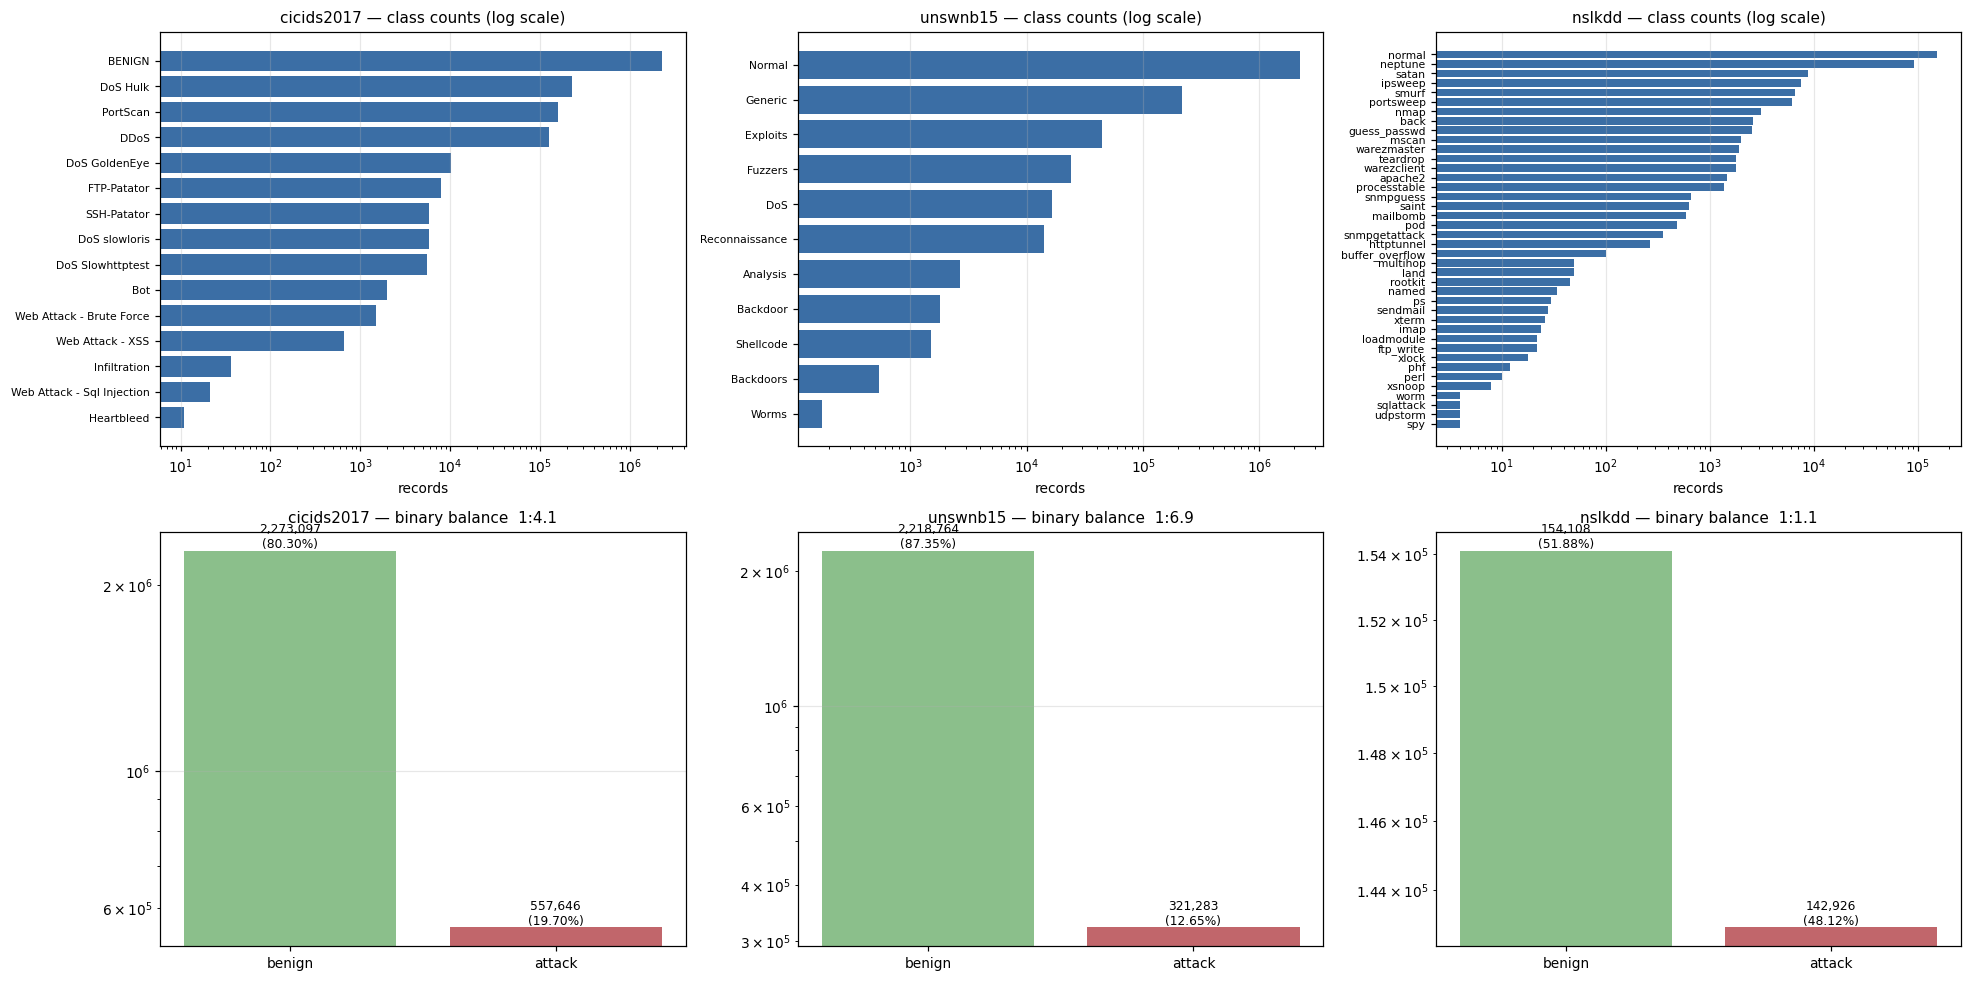

In [ ]:
# --- Figure 1: class distributions -----------------------------------------
n = len(DATASETS)
fig, axes = plt.subplots(2, n, figsize=(6 * n, 9))
axes = np.atleast_2d(axes)

for j, (name, df) in enumerate(DATASETS.items()):
    vc = df["label_raw"].value_counts()
    ax = axes[0, j]
    ax.barh(range(len(vc)), vc.values, color="#3b6ea5")
    ax.set_yticks(range(len(vc)))
    ax.set_yticklabels([str(x)[:28] for x in vc.index], fontsize=7)
    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.set_title(f"{name} — class counts (log scale)", fontsize=10)
    ax.set_xlabel("records")
    ax.grid(axis="x", alpha=.3)

    y = binary_label(df["label_raw"])
    ax2 = axes[1, j]
    counts = [int((y == 0).sum()), int(y.sum())]
    bars = ax2.bar(["benign", "attack"], counts, color=["#8bbf8b", "#c1666b"])
    ax2.set_yscale("log")
    for b, c in zip(bars, counts):
        ax2.text(b.get_x() + b.get_width() / 2, c, f"{c:,}\n({100*c/len(df):.2f}%)",
                 ha="center", va="bottom", fontsize=8)
    ax2.set_title(f"{name} — binary balance  1:{LABELS[name]['binary_imbalance_ratio']}",
                  fontsize=10)
    ax2.grid(axis="y", alpha=.3)

plt.tight_layout()
plt.savefig(FIGURES / "fig01_class_distributions.png")
plt.show()


This cell visualises the data quality problems found in Section 6.
Missing and infinite cell counts are shown per dataset on one axis.
Duplicate row percentages are shown alongside for direct comparison.
The figure justifies the cleaning steps that Notebook 02 will apply.

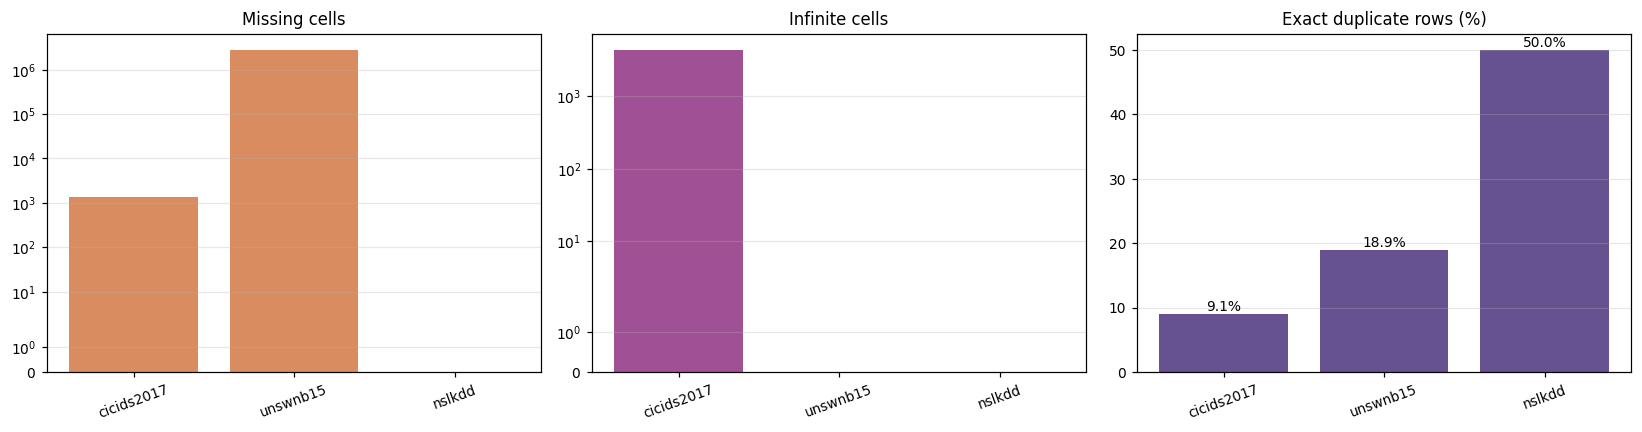

In [ ]:
# --- Figure 2: data quality summary ----------------------------------------
q = pd.DataFrame(QUALITY).T
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(q.index, q["total_missing_cells"].astype(float), color="#d98c5f")
axes[0].set_title("Missing cells"); axes[0].set_yscale("symlog")

axes[1].bar(q.index, q["total_inf_cells"].astype(float), color="#a05195")
axes[1].set_title("Infinite cells"); axes[1].set_yscale("symlog")

axes[2].bar(q.index, q["duplicate_pct_all"].astype(float), color="#665191")
axes[2].set_title("Exact duplicate rows (%)")
for i, v in enumerate(q["duplicate_pct_all"].astype(float)):
    axes[2].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

for ax in axes:
    ax.grid(axis="y", alpha=.3)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIGURES / "fig02_data_quality.png")
plt.show()


This cell plots the strongest single feature separability scores per dataset.
Bars in the red zone indicate features that alone almost solve the task.
Such features are usually testbed artefacts rather than transferable signal.
This figure directly evidences the leakage control claim in Section 3.5.

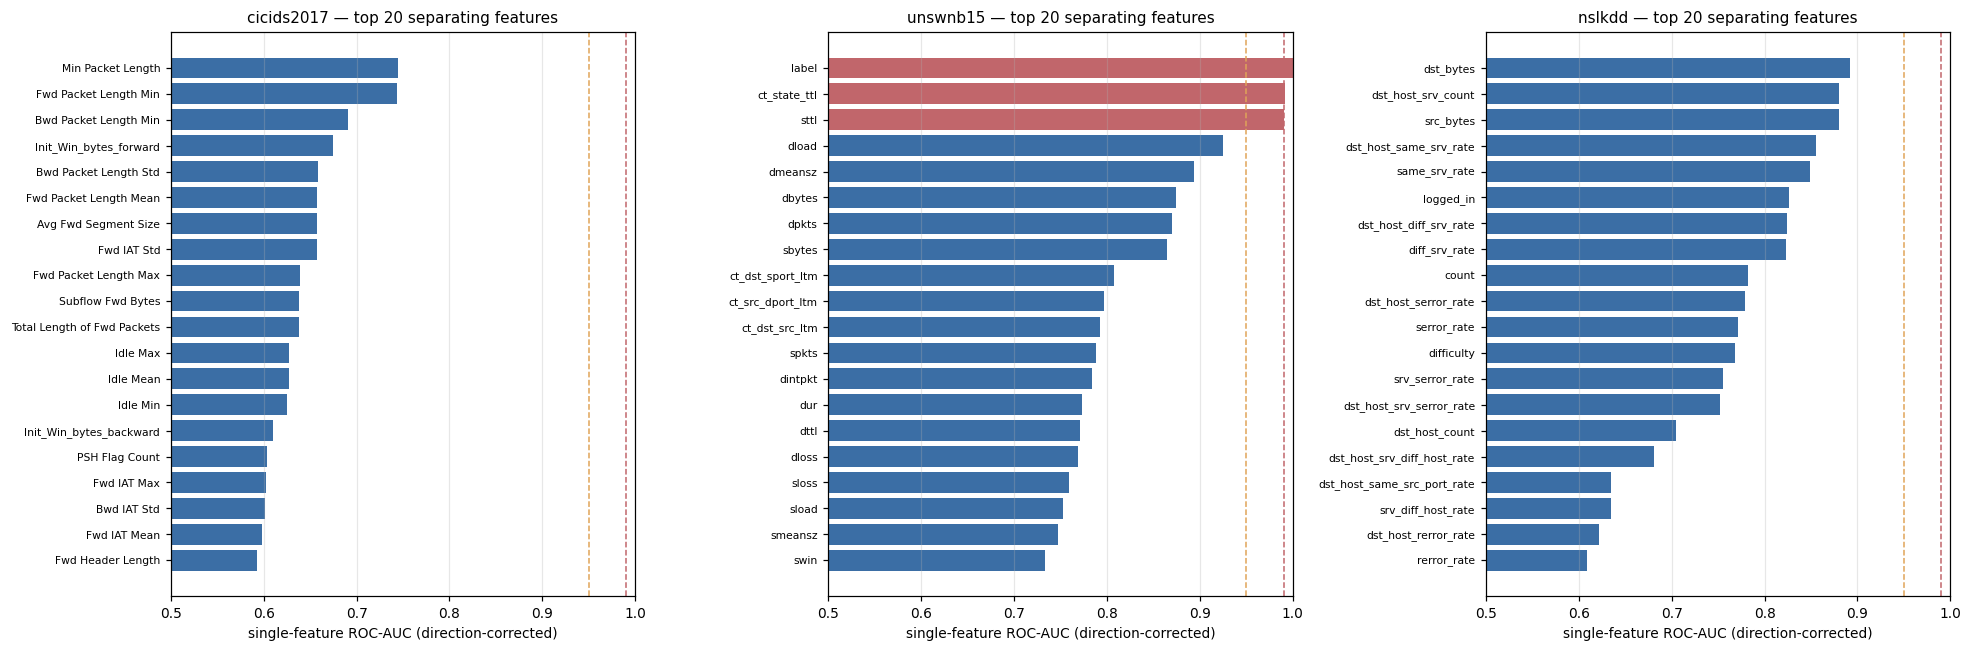

In [ ]:
# --- Figure 3: single-feature leakage screen -------------------------------
fig, axes = plt.subplots(1, len(AUCS), figsize=(6 * len(AUCS), 6))
axes = np.atleast_1d(axes)
for ax, (name, a) in zip(axes, AUCS.items()):
    top = a.head(20).iloc[::-1]
    colors = ["#c1666b" if v >= .99 else "#e0a458" if v >= .95 else "#3b6ea5"
              for v in top.auc]
    ax.barh(range(len(top)), top.auc, color=colors)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([c[:30] for c in top.feature], fontsize=7)
    ax.axvline(.95, ls="--", c="#e0a458", lw=1)
    ax.axvline(.99, ls="--", c="#c1666b", lw=1)
    ax.set_xlim(.5, 1.0)
    ax.set_xlabel("single-feature ROC-AUC (direction-corrected)")
    ax.set_title(f"{name} — top 20 separating features", fontsize=10)
    ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.savefig(FIGURES / "fig03_leakage_screen.png")
plt.show()


This cell compares shared feature distributions between the transfer datasets.
Visible distribution shift is the mechanism behind cross dataset performance collapse.
Values are plotted on a log scale because these features are heavily skewed.
This figure supports the RQ2 discussion whatever the transfer result turns out to be.

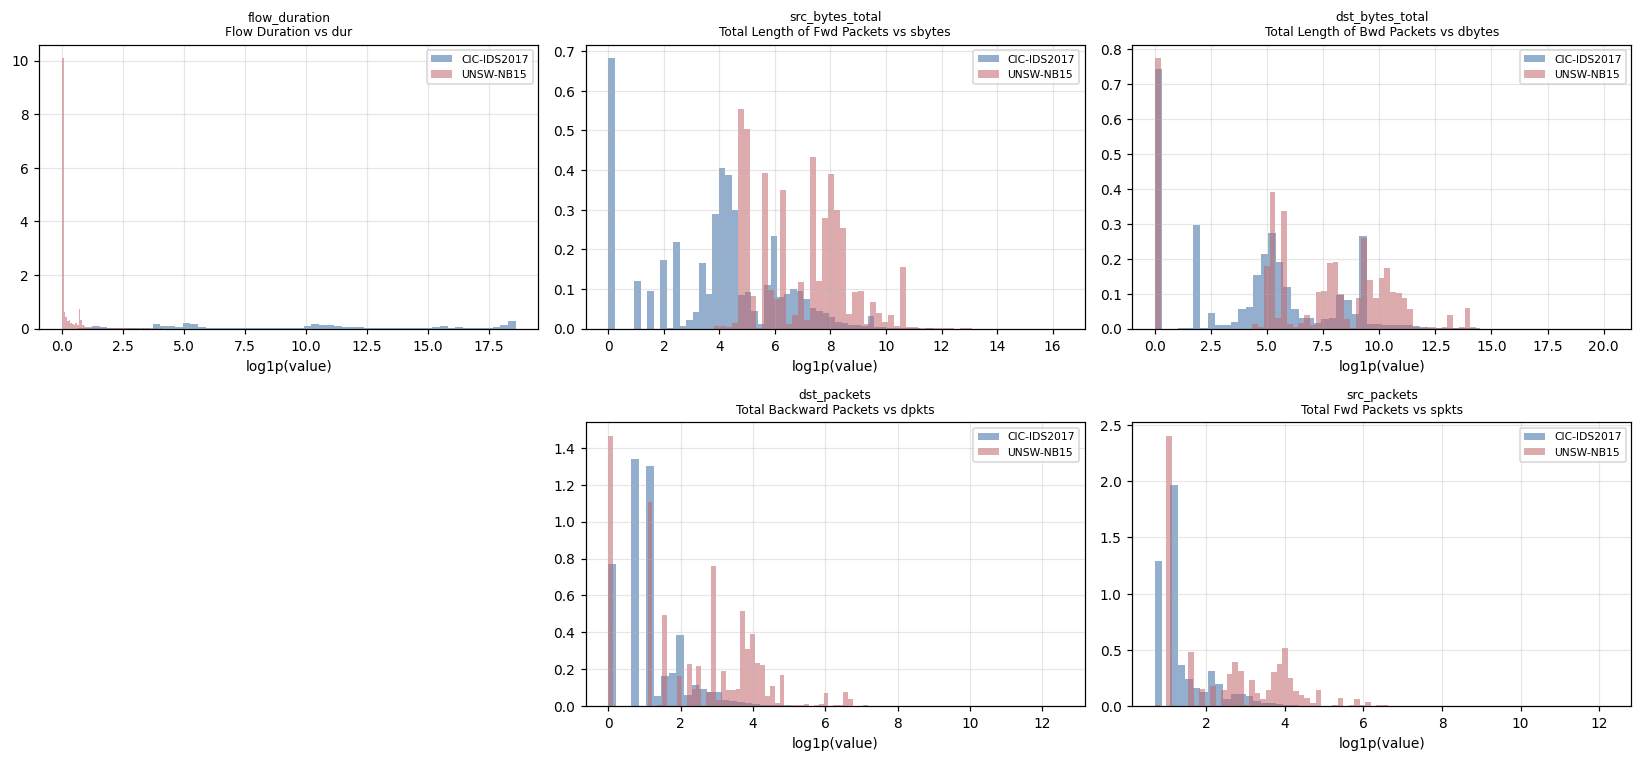

In [ ]:
# --- Figure 4: covariate shift between transfer pair -----------------------
# transfer pair to visualise
shared = crosswalk[crosswalk.cicids2017.notna() & crosswalk.unswnb15.notna()]

if len(shared) and "cicids2017" in DATASETS and "unswnb15" in DATASETS:
    show = shared.head(6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
        a = pd.to_numeric(DATASETS["cicids2017"][r.cicids2017], errors="coerce")
        b = pd.to_numeric(DATASETS["unswnb15"][r.unswnb15], errors="coerce")
        a = a.replace([np.inf, -np.inf], np.nan).dropna()
        b = b.replace([np.inf, -np.inf], np.nan).dropna()
        if a.empty or b.empty:
            ax.set_visible(False); continue
        a = np.log1p(a.clip(lower=0).sample(min(len(a), 100_000), random_state=SEED))
        b = np.log1p(b.clip(lower=0).sample(min(len(b), 100_000), random_state=SEED))
        ax.hist(a, bins=60, alpha=.55, density=True, label="CIC-IDS2017", color="#3b6ea5")
        ax.hist(b, bins=60, alpha=.55, density=True, label="UNSW-NB15",  color="#c1666b")
        ax.set_title(f"{r.concept}\n{r.cicids2017} vs {r.unswnb15}", fontsize=8)
        ax.set_xlabel("log1p(value)"); ax.legend(fontsize=7); ax.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(FIGURES / "fig04_covariate_shift.png")
    plt.show()
else:
    print("Skipped: need both CIC-IDS2017 and UNSW-NB15 loaded with shared concepts.")


This cell shows the feature correlation structure of the primary dataset.
Highly correlated blocks indicate redundancy that Feature Set C should remove.
Logistic Regression is sensitive to collinearity while Random Forest is not.
This informs both the feature selection design and the model interpretation.

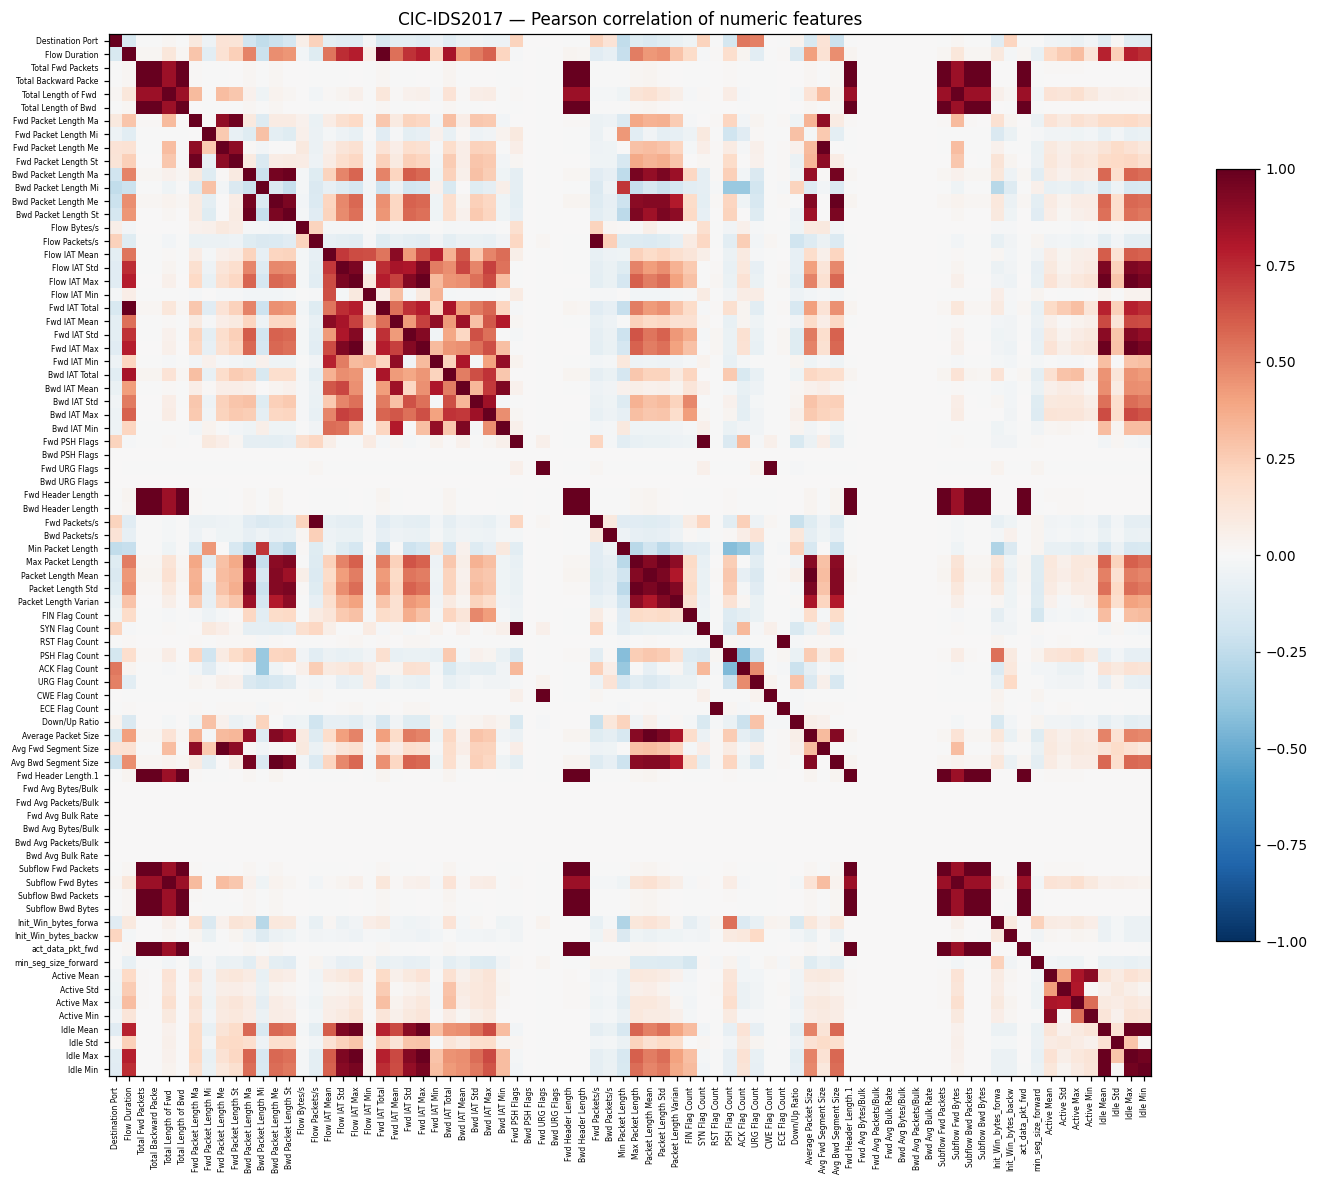


Feature pairs with |r| > 0.95: 68


,level_0,level_1,r
632,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
360,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000
288,Total Backward Packets,Subflow Bwd Packets,1.000000
212,Total Fwd Packets,Subflow Fwd Packets,1.000000
2479,RST Flag Count,ECE Flag Count,1.000000
2077,Fwd Header Length,Fwd Header Length.1,1.000000
1984,Fwd URG Flags,CWE Flag Count,1.000000
1888,Fwd PSH Flags,SYN Flag Count,1.000000
899,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
434,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000


In [ ]:
# --- Figure 5: correlation structure of the primary dataset ----------------
if "cicids2017" in DATASETS:
    df = DATASETS["cicids2017"]
    numf = [c for c in df.select_dtypes(include=[np.number]).columns
            if not c.startswith("__")]
    sub = (df[numf].replace([np.inf, -np.inf], np.nan)
                    .sample(min(len(df), 150_000), random_state=SEED))
    corr = sub.corr().fillna(0)

    fig, ax = plt.subplots(figsize=(13, 11))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
    ax.set_xticklabels([c[:20] for c in corr.columns], rotation=90, fontsize=5)
    ax.set_yticklabels([c[:20] for c in corr.index], fontsize=5)
    ax.set_title("CIC-IDS2017 — Pearson correlation of numeric features", fontsize=11)
    fig.colorbar(im, shrink=.7)
    plt.tight_layout()
    plt.savefig(FIGURES / "fig05_correlation.png")
    plt.show()

    hi = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
              .stack().rename("r").reset_index())
    hi = hi[hi.r.abs() > 0.95].sort_values("r", key=abs, ascending=False)
    print(f"\nFeature pairs with |r| > 0.95: {len(hi)}")
    display(hi.head(20))
    hi.to_csv(REPORTS / "cic_high_correlation_pairs.csv", index=False)
    MANIFEST["findings"]["cic_pairs_r_gt_095"] = int(len(hi))


## 11. Export artefacts

This cell writes every profiling artefact to the reports folder as CSV and JSON.
These files are the inputs needed in order to design Notebook 02 correctly.
The run manifest is finalised here with timestamps and version records.
Nothing in later notebooks should re-derive facts that are recorded here.

In [ ]:
# --- Export everything -----------------------------------------------------
struct_df.to_csv(REPORTS / "structure.csv", index=False)
pd.DataFrame(QUALITY).T.to_csv(REPORTS / "quality_summary.csv")
pd.DataFrame(LABELS).T.to_csv(REPORTS / "label_summary.csv")

for name in DATASETS:
    QUALITY_DETAIL[name].to_csv(REPORTS / f"quality_detail_{name}.csv")
    AUCS[name].to_csv(REPORTS / f"leakage_auc_{name}.csv", index=False)
    if len(STRUCTURAL[name]):
        STRUCTURAL[name].to_csv(REPORTS / f"leakage_structural_{name}.csv", index=False)
    DATASETS[name]["label_raw"].value_counts().to_csv(REPORTS / f"labels_{name}.csv")
    inv = pd.DataFrame({
        "column": [c for c in DATASETS[name].columns if not c.startswith("__")],
    })
    inv["dtype"] = [str(DATASETS[name][c].dtype) for c in inv.column]
    inv["n_unique"] = [int(DATASETS[name][c].nunique(dropna=False)) for c in inv.column]
    inv["pct_missing"] = [round(100 * DATASETS[name][c].isna().mean(), 4) for c in inv.column]
    inv.to_csv(REPORTS / f"feature_inventory_{name}.csv", index=False)

MANIFEST["run_finished_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
MANIFEST["unsw_variant"] = unsw_variant
(REPORTS / "run_manifest_nb01.json").write_text(json.dumps(MANIFEST, indent=2, default=str))

print("Written to", REPORTS)
for p in sorted(REPORTS.glob("*")):
    print(f"  {p.name:44s} {p.stat().st_size/1024:8.1f} KB")
print("\nFigures in", FIGURES)
for p in sorted(FIGURES.glob("*")):
    print(f"  {p.name}")


Written to /content/drive/MyDrive/nids_benchmark/reports/nb01
  cic_high_correlation_pairs.csv                    3.6 KB
  feature_crosswalk.csv                             0.8 KB
  feature_inventory_cicids2017.csv                  2.5 KB
  feature_inventory_nslkdd.csv                      1.2 KB
  feature_inventory_unswnb15.csv                    1.2 KB
  file_hashes.json                                  3.4 KB
  label_summary.csv                                 0.2 KB
  labels_cicids2017.csv                             0.3 KB
  labels_nslkdd.csv                                 0.5 KB
  labels_unswnb15.csv                               0.2 KB
  leakage_auc_cicids2017.csv                        3.4 KB
  leakage_auc_nslkdd.csv                            1.6 KB
  leakage_auc_unswnb15.csv                          1.6 KB
  leakage_structural_cicids2017.csv                 0.1 KB
  leakage_structural_nslkdd.csv                     0.1 KB
  leakage_structural_unswnb15.csv                   0